In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, fftshift
from scipy.signal import convolve
from scipy.ndimage import gaussian_filter as gf

## Extraction of the 2D aperture function from an image

$A(x, y) = A_{ij} (x_i, y_j)$

### Roman Space Telescope

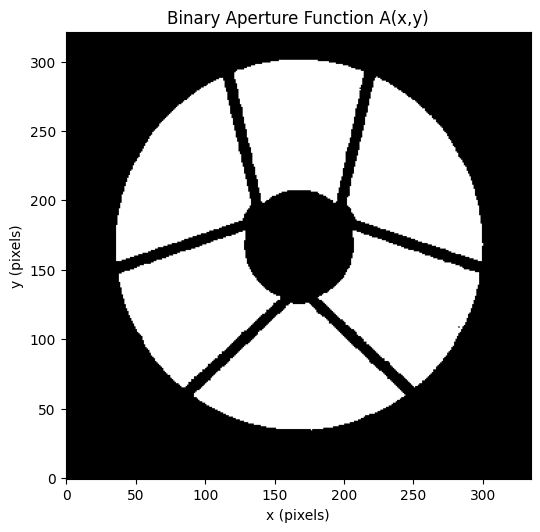

Shape of A: (322, 335)
Unique values: [0. 1.]


In [66]:
# Load image
img = Image.open("./resources/roman_aperture2.png").convert("L")

#produce the aperture function from image
image = np.array(img)
threshold = 128
A = (image > threshold).astype(float)




# Display aperture function
plt.figure(figsize=(6, 6))
plt.imshow(A, cmap="gray", origin="lower")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.title("Binary Aperture Function A(x,y)")
plt.show()

print("Shape of A:", A.shape)
print("Unique values:", np.unique(A))

### JWST

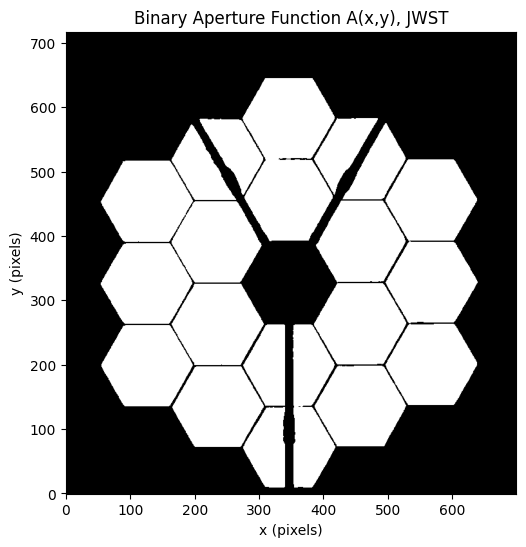

Shape of A: (322, 335)
Unique values: [0. 1.]


In [67]:
# Load image
img2 = Image.open("./resources/jwst_aperture.png").convert("L")

#produce the aperture function from image
image2 = np.array(img2)
threshold = 128
A2 = (image2 > threshold).astype(float)




# Display aperture function
plt.figure(figsize=(6, 6))
plt.imshow(A2, cmap="gray", origin="lower")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.title("Binary Aperture Function A(x,y), JWST")
plt.show()

print("Shape of A:", A.shape)
print("Unique values:", np.unique(A))

## Taking the fourier transform of Aperture 

$$V(u, v) = \int_{-\infty}^{\infty} \int_{-\infty}^{\infty} A(x, y)e^{-i(ux + vy)} dxdy$$

PSF(Point Spread Function) is the modulous square of $V(u, v)$

$$PSF(u, v) = |V(u, v)|^2$$

### Nancy Grace Roman Space Telescope

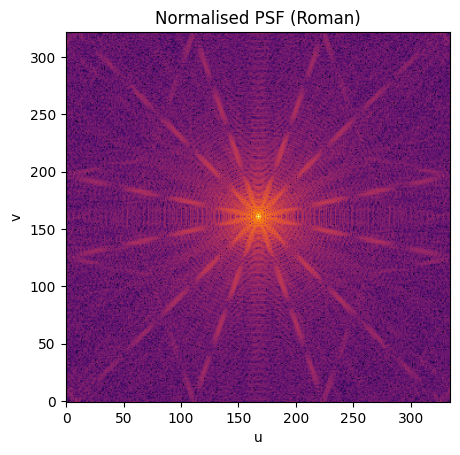

In [68]:
#Taking fourier transform of the aperture
V = fft2(A)
V = fftshift(V)

#computing the psf
psf = np.abs(V**2)
psf /= psf.max()

#plotting the psf
plt.imshow(np.log10(psf + 1e-10),
origin='lower', 
cmap='inferno')

plt.title('Normalised PSF (Roman)')
plt.xlabel('u')
plt.ylabel('v')
plt.show()


### James Webb Space Telescope

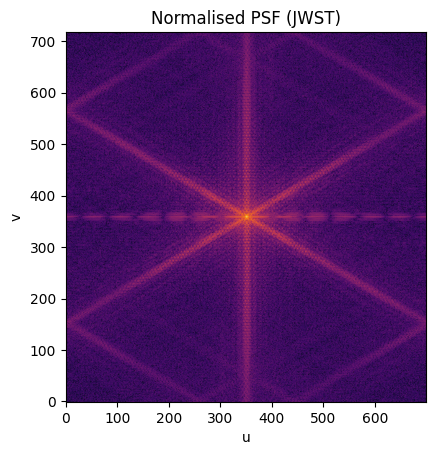

In [69]:
#Taking fourier transform of the aperture
V2 = fft2(A2)
V2 = fftshift(V2)

#computing the psf
psf2 = np.abs(V2**2)
psf2 /= psf2.max()

#plotting the psf
plt.imshow(np.log10(psf2 + 1e-10),
origin='lower', 
cmap='inferno')

plt.title('Normalised PSF (JWST)')
plt.xlabel('u')
plt.ylabel('v')
plt.show()

### Generating star fields by adding delta functions
$$I_{stars} = \sum_{ij} K_{ij} \cdot \delta (u - a_i) \delta (v - b_j) $$

In [70]:
#defining delta functions
def delta(u , v, amp, shape):
    star = np.zeros(shape)
    star[u, v] = amp 
    return star

In [71]:
print(psf.max())
print(psf.min())
print(len(psf))
amp_rng = np.linspace(1e-6, 1e-10, 300)

1.0
5.239656164780425e-12
322


In [58]:
#generating random positions and amplitudes for stars
x = []
y = []
amp = []
amp2 = []
for i in range(30):
    x.append(np.random.randint(10, 322))
    y.append(np.random.randint(10, 322))
    amp.append(psf[np.random.randint(0, 300), np.random.randint(0, 300)])
    amp2.append(amp_rng[np.random.randint(300)])


amp2[11] = 1e-5
amp2[28] = 1e-4

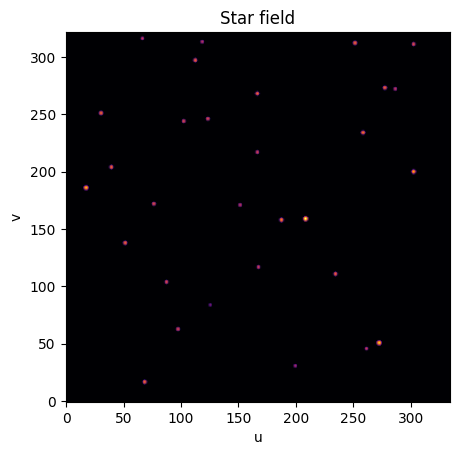

In [65]:
#populating the star field
starfield = np.zeros(np.shape(psf))
for i in range(30):
    starfield += delta(x[i], y[i], amp[i], np.shape(psf))

#plotting 
plt.imshow(np.log10(gf(starfield, sigma = 0.5) + 1e-11),
origin='lower', 
cmap='inferno')

plt.title('Star field')
plt.xlabel('u')
plt.ylabel('v')
plt.show()

## Final output
The final output image is obtained by taking the convolution of PSF with the starfield 
$$I_{image} = \int_{-\infty}^{\infty} \int_{-\infty}^{\infty} PSF(u, v)I_{star}(u - u', v - v') du'dv'$$

### Nancy Grace Roman Space Telescope

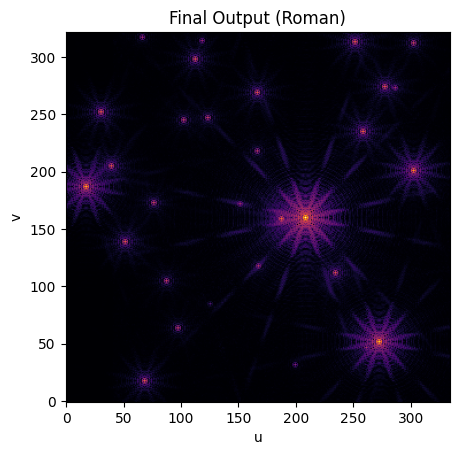

In [60]:
output_starfield = convolve(psf, starfield, mode = 'same', method = 'auto')


plt.imshow(np.log10(output_starfield + 1e-10),
origin='lower', 
cmap='inferno')

plt.title('Final Output (Roman)')
plt.xlabel('u')
plt.ylabel('v')
plt.show()

### James Webb Space Telescope

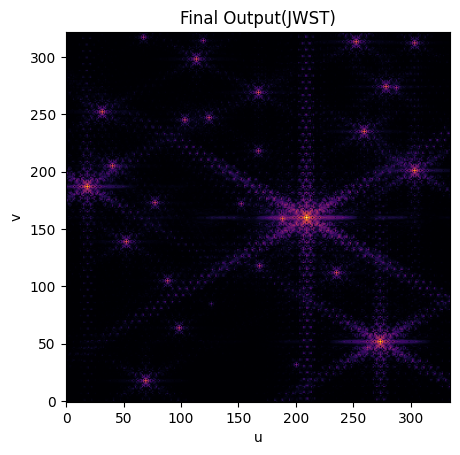

In [61]:
output_starfield3 = convolve(starfield, psf2, mode = 'same', method = 'auto')


plt.imshow(np.log10(output_starfield3 + 1e-10),
origin='lower', 
cmap='inferno')

plt.title('Final Output(JWST)')
plt.xlabel('u')
plt.ylabel('v')
#plt.xlim(150, 550)
#plt.ylim(200, 550)
plt.show()